# Regression Model Validation

This notebook is used to train and evaluate the regression model to predict fire numbers based on wind data.

## 1. Import Necessary Libraries and Data Path

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

notebook_dir = os.path.abspath('')
project_root = os.path.dirname(os.path.dirname(notebook_dir))


import data_processor
data_processor.DATA_PATH = os.path.join(project_root, 'data', 'processed')

## 2. Data Preparation

In [8]:
print("\nPreparing data...")
merged_data, wind_cols = data_processor.prepare_weather_fire_data(
    data_type='count', 
    weather_types=['wind'] 
)


Preparing data...

Data shape after merging:
Data shape: (1625, 30)
Data type selected: ['wind']


## 3. Split Dataset

In [9]:
print("\nBegin splitting data...")
(X_train, y_train), (X_val, y_val), (X_test, y_test) = data_processor.split_dataset(
    merged_data=merged_data,
    feature_columns=wind_cols,
    target_column='fire_count'
)




Begin spliting data...
Data set splited successfully:
Training set size: 975 (60.00%)
Validating set size: 325 (20.00%)
Testing set size: 325 (20.00%)


## 4. Pre-process Features

In [10]:
from data_processor import preprocess_features

print("\nPre-processing features...")
X_train_processed, X_val_processed, X_test_processed = preprocess_features(X_train, X_val, X_test)


Pre-processing features...

Data pre-processing results:
Training set shape: (975, 29)
Validating set shape: (325, 29)
Testing set shape: (325, 29)

Check missing-values in the pre-processed data:
Missing value of training set: 0
Missing value of validating set: 0
Missing value of testing set: 0


## 5. Define the Function to Train and Evaluate Two Models

In [11]:
def plot_trends(merged_data, y_pred, model_name, humid_cols, val_indices):

    val_data = merged_data.loc[val_indices]
    
    predictions_df = pd.DataFrame({
        'Actual': val_data['fire_count'],
        'Predicted': y_pred
    }, index=val_data.index)

    avg_wind = val_data[humid_cols].mean(axis=1)
    
    plt.figure(figsize=(12, 6))
    plt.scatter(avg_wind, predictions_df['Actual'], 
               alpha=0.5, label='Actual Data')
    plt.scatter(avg_wind, predictions_df['Predicted'], 
               alpha=0.5, label='Predicted Data')
    
    z1 = np.polyfit(avg_wind, predictions_df['Actual'], 1)
    p1 = np.poly1d(z1)
    plt.plot(avg_wind, p1(avg_wind), "r--", alpha=0.8, label='Actual Trend')
    
    z2 = np.polyfit(avg_wind, predictions_df['Predicted'], 1)
    p2 = np.poly1d(z2)
    plt.plot(avg_wind, p2(avg_wind), "g--", alpha=0.8, label='Predicted Trend')
    
    plt.title(f'{model_name} - Average wind speed vs Fire Count')
    plt.xlabel('Average wind speed')
    plt.ylabel('Fire Count')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

def train_and_evaluate_models(X_train, X_val, y_train, y_val, merged_data, humid_cols):
    global feature_importance, linear_importance
    models = {
        'Linear Regression': LinearRegression(),
        'Random Forest': RandomForestRegressor(
            n_estimators=100,  
            max_depth=10,      
            random_state=42
        )
    }
    
    results = {}
    
    for name, model in models.items():
        print(f"\nTraining {name}...")

        model.fit(X_train, y_train)
        
        y_pred = model.predict(X_val)
        
        mse = mean_squared_error(y_val, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_val, y_pred)
        
        print(f"{name} Evaluation Results:")
        print(f"Mean Squared Error (MSE): {mse:.4f}")
        print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
        print(f"R-squared (R²): {r2:.4f}")
        
        plt.figure(figsize=(10, 6))
        plt.scatter(y_val, y_pred, alpha=0.5)
        plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
        plt.title(f'{name} - Actual vs Predicted')
        plt.xlabel('Actual Fire Count')
        plt.ylabel('Predicted Fire Count')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()

        plot_trends(merged_data, y_pred, name, humid_cols, X_val.index)
        
        if name == 'Random Forest':
            # Random Forest feature importance
            feature_importance = pd.Series(
                model.feature_importances_,
                index=X_train.columns
            ).sort_values(ascending=True)
            
            plt.figure(figsize=(12, 8))
            feature_importance.plot(kind='barh')
            plt.title('Random Forest - Feature Importance')
            plt.xlabel('Importance Score')
            plt.ylabel('Weather Stations')
            plt.grid(True, linestyle='--', alpha=0.3)
            plt.tight_layout()
            plt.show()
        
        if name == 'Linear Regression':
            # Linear Regression feature importance (absolute coefficients)
            linear_importance = pd.Series(
                np.abs(model.coef_),
                index=X_train.columns
            ).sort_values(ascending=True)
            
            plt.figure(figsize=(12, 8))
            linear_importance.plot(kind='barh')
            plt.title('Linear Regression - Feature Importance')
            plt.xlabel('Absolute Coefficient Value')
            plt.ylabel('Weather Stations')
            plt.grid(True, linestyle='--', alpha=0.3)
            plt.tight_layout()
            plt.show()
            
        results[name] = {
            'model': model,
            'mse': mse,
            'rmse': rmse,
            'r2': r2,
            'predictions': y_pred
        }
        if name == 'Random Forest':
            print("\nRandom Forest - Top 10 Most Important Features:")
            print(feature_importance.tail(10))
        
        if name == 'Linear Regression':
            print("\nLinear Regression - Top 10 Most Important Features:")
            print(linear_importance.tail(10))

    print("\nModel Performance Comparison:")
    performance_comparison = pd.DataFrame({
        'MSE': [results[model]['mse'] for model in models],
        'RMSE': [results[model]['rmse'] for model in models],
        'R²': [results[model]['r2'] for model in models]
    }, index=models.keys())
    print(performance_comparison)
    
    return results

## 6. Execute Model Training and Evaluation


Starting model training and evaluation...

Training Linear Regression...
Linear Regression Evaluation Results:
Mean Squared Error (MSE): 142.8927
Root Mean Squared Error (RMSE): 11.9538
R-squared (R²): 0.1951


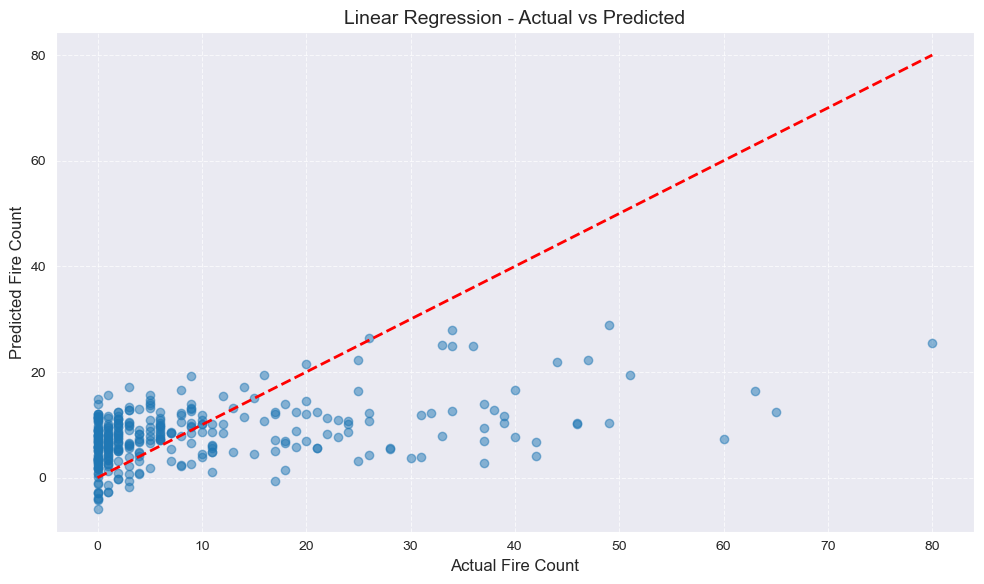

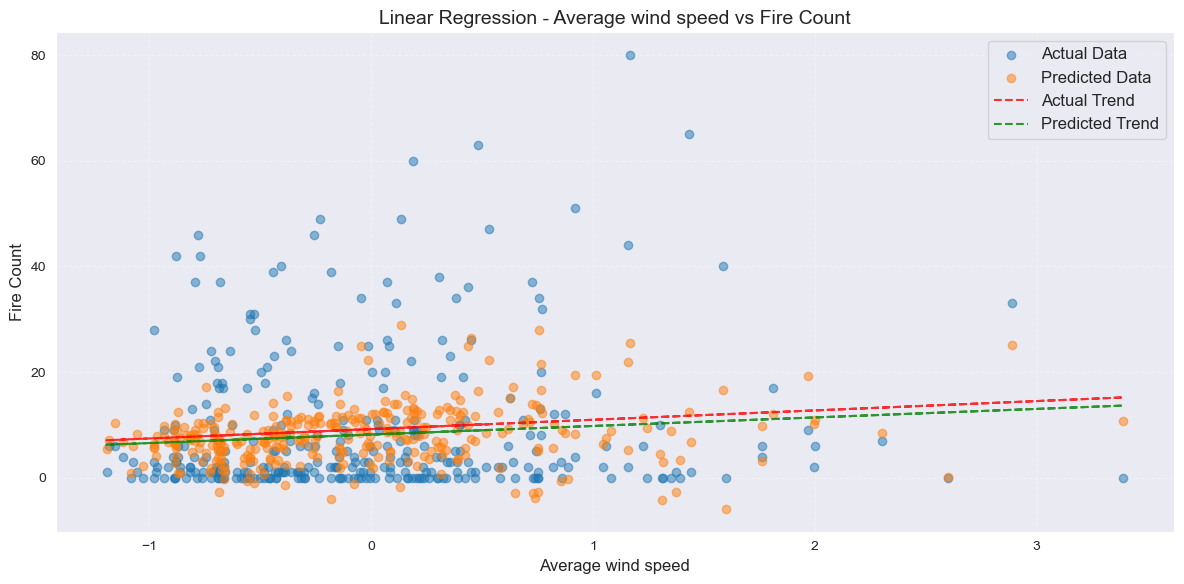

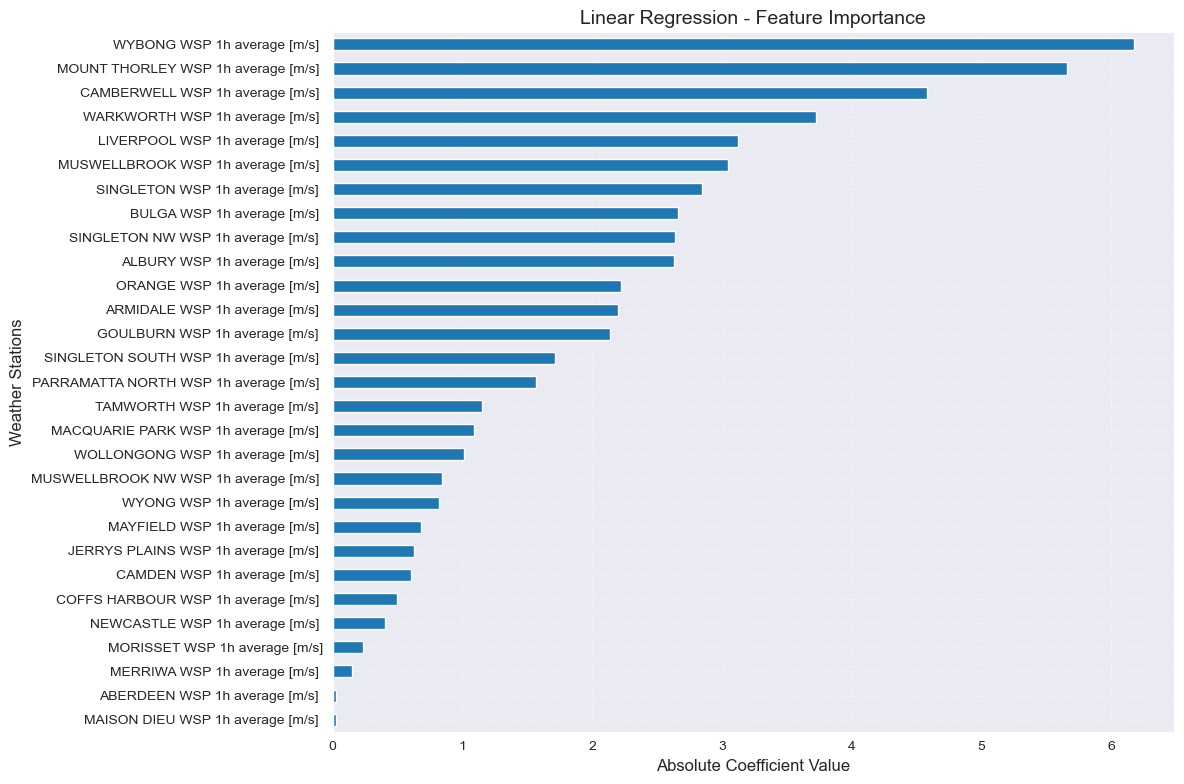


Linear Regression - Top 10 Most Important Features:
ALBURY WSP 1h average [m/s]            2.629173
SINGLETON NW WSP 1h average [m/s]      2.635721
BULGA WSP 1h average [m/s]             2.661283
SINGLETON WSP 1h average [m/s]         2.846884
MUSWELLBROOK WSP 1h average [m/s]      3.051052
LIVERPOOL WSP 1h average [m/s]         3.125760
WARKWORTH WSP 1h average [m/s]         3.722885
CAMBERWELL WSP 1h average [m/s]        4.581681
MOUNT THORLEY WSP 1h average [m/s]     5.658055
WYBONG WSP 1h average [m/s]            6.176534
dtype: float64

Training Random Forest...
Random Forest Evaluation Results:
Mean Squared Error (MSE): 146.2983
Root Mean Squared Error (RMSE): 12.0954
R-squared (R²): 0.1759


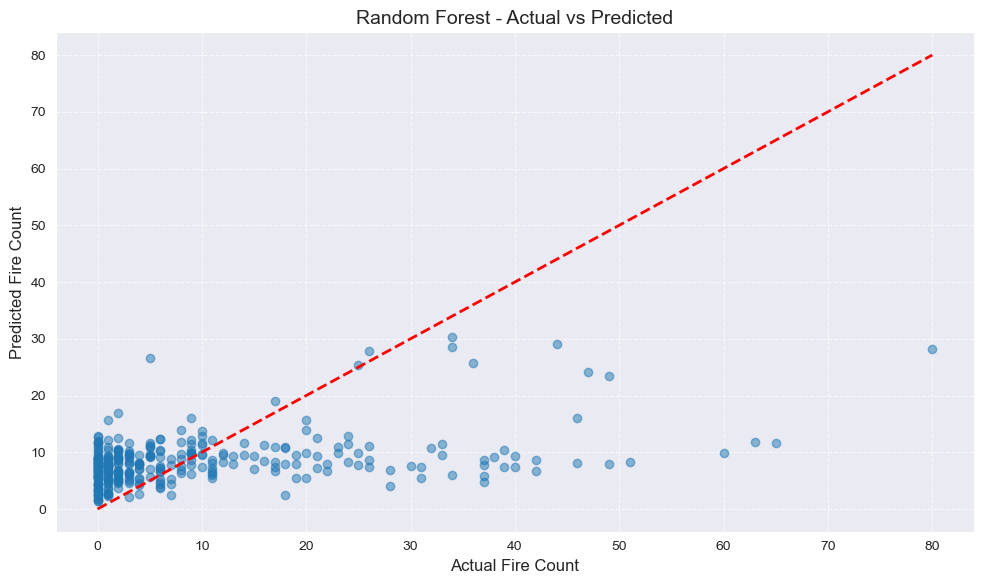

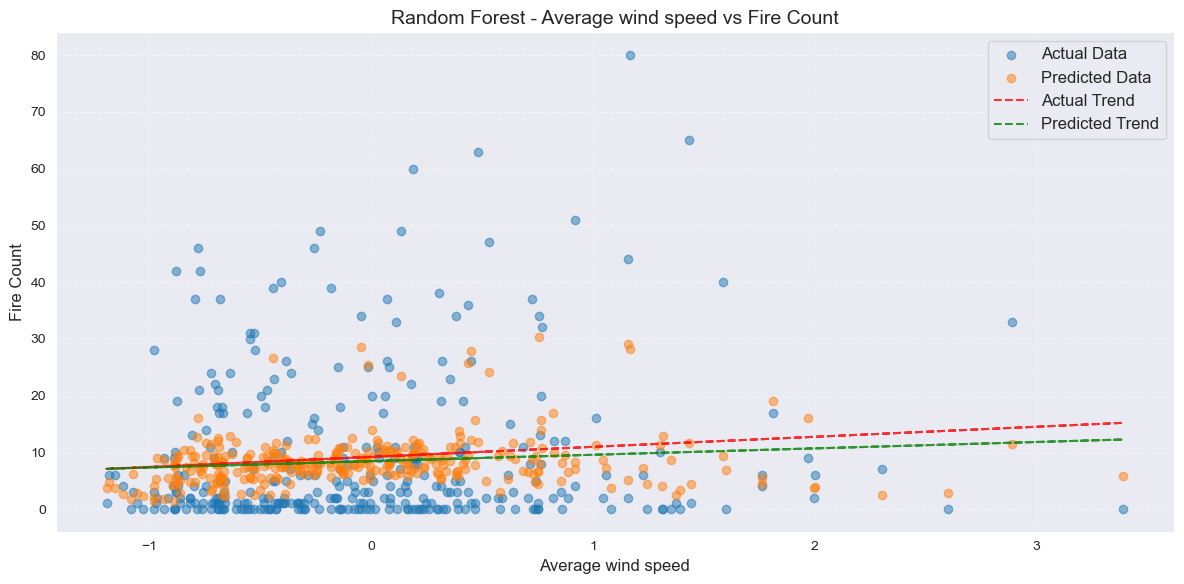

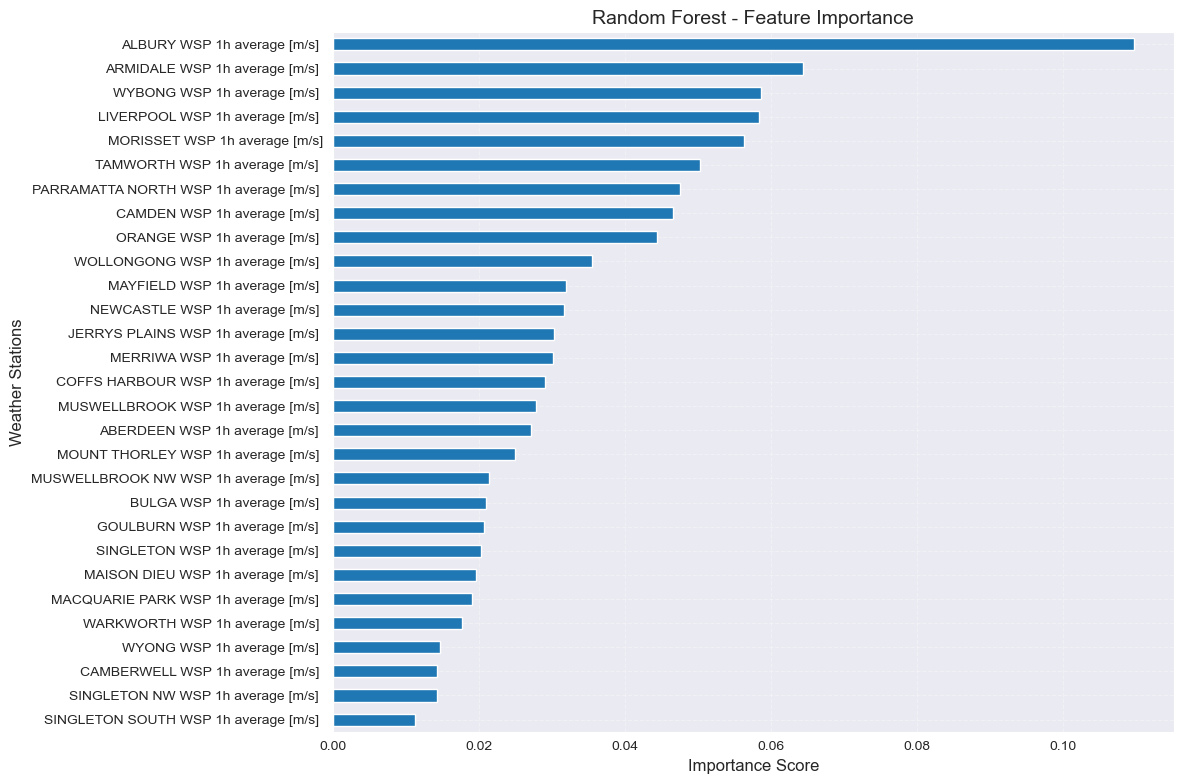


Random Forest - Top 10 Most Important Features:
WOLLONGONG WSP 1h average [m/s]           0.035547
ORANGE WSP 1h average [m/s]               0.044394
CAMDEN WSP 1h average [m/s]               0.046658
PARRAMATTA NORTH WSP 1h average [m/s]     0.047520
TAMWORTH WSP 1h average [m/s]             0.050284
MORISSET WSP 1h average [m/s]             0.056301
LIVERPOOL WSP 1h average [m/s]            0.058441
WYBONG WSP 1h average [m/s]               0.058615
ARMIDALE WSP 1h average [m/s]             0.064446
ALBURY WSP 1h average [m/s]               0.109706
dtype: float64

Model Performance Comparison:
                          MSE       RMSE        R²
Linear Regression  142.892662  11.953772  0.195110
Random Forest      146.298324  12.095384  0.175927


C:\Users\18400\AppData\Local\Temp\ipykernel_14700\611400557.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=45)
C:\Users\18400\AppData\Local\Temp\ipykernel_14700\611400557.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=45)
C:\Users\18400\AppData\Local\Temp\ipykernel_14700\611400557.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=45)


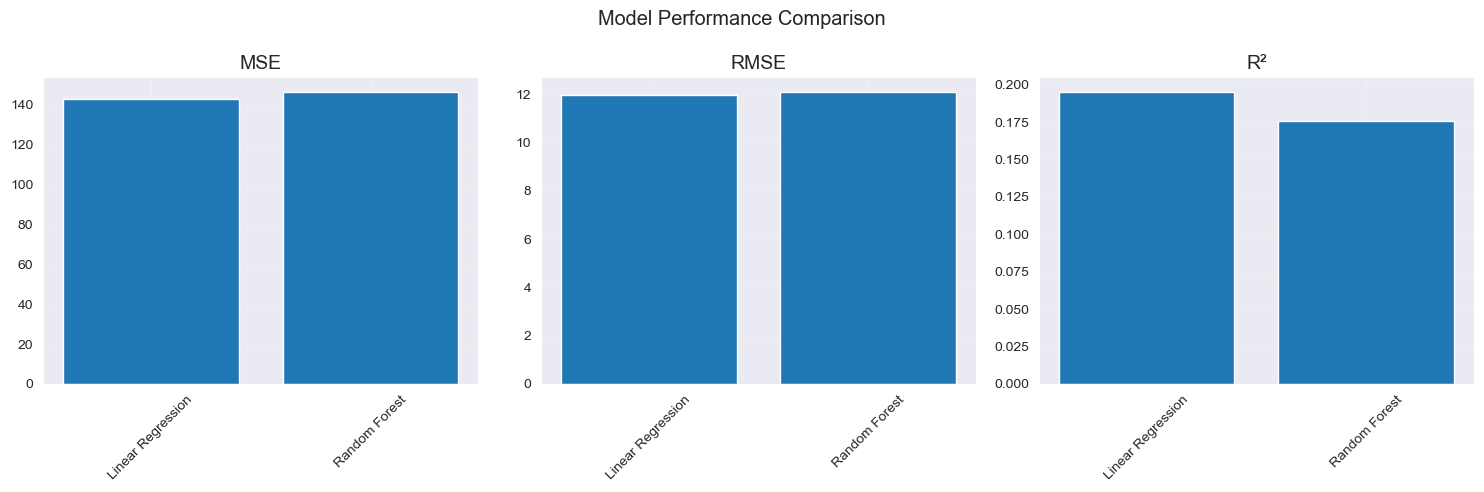

In [12]:
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

print("\nStarting model training and evaluation...")
model_results = train_and_evaluate_models(X_train_processed, X_val_processed, y_train, y_val, merged_data, wind_cols)

metrics = ['MSE', 'RMSE', 'R²']
model_names = list(model_results.keys())
performance_data = []

for metric in metrics:
    if metric == 'MSE':
        values = [results['mse'] for results in model_results.values()]
    elif metric == 'RMSE':
        values = [results['rmse'] for results in model_results.values()]
    else:  # R²
        values = [results['r2'] for results in model_results.values()]
    performance_data.append(values)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Model Performance Comparison')

for i, (metric, ax) in enumerate(zip(metrics, axes)):
    ax.bar(model_names, performance_data[i])
    ax.set_title(metric)
    ax.set_xticklabels(model_names, rotation=45)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()